**KURULUM**

Kullancağımız kütüphaneleri içe aktaracağız.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier


# **1. Aşama - Problem Tanımı**

**Soru**: Molekülün kimyasal özelliklerinden doğada/vücutta kolayca parçalanıp parçalanmayacağını (biyobozunurluk riskini) tahmin et.

* **Hedef(y)**: *target_class* (1 = Not Ready Biodegradable / Riskli , 0 = Ready Biodegradable / Güvenli)

* **Özellikler(x)**: Ağır atom sayısı (nHM) , karbon yüzdesi (C%) , Oksijen/Azot sayıları (nO, nN) , moleküler bağ ve yapı kat sayıları , (toplam 41 moleküler özellik)

* **Neden Önemli?**: Yeni geliştirilen bir ilacın veya kimyasal bileşenin doğada birikip zehirli etki yaratıp yaratmayacağını önceden tahmin ederek çevre sağlığını ve biyo-güvenliği korumak.

# **2. Aşama - Veriyi Oku ve Tanı**

Veriyi 'biodeg.csv' dosyasından okuyoruz.

In [2]:
# Sütun isimlerimizi tanımlayalım (İlk 41 moleküler özellik + Hedef Değişken)
kolonlar = [
    'SpMax_L' , 'J_Dz_e' , 'nHM' , 'F01_NN' , 'F04_CN' , 'NssssC' , 'nCb' , 'C_percent' , 'nCp' , 'nO' ,
    'F03_CN' , 'SdssC' , 'HyWi_B_m' , 'LOC' , 'SM6_L' , 'F03_CO' , 'Me' , 'Mi' , 'nN_N' , 'nArNO2' , 'nCRX3' ,
    'SpPosA_B_p' , 'nCIR' , 'B01_CBr' , 'B03_CCl' , 'N_073' , 'SpMax_A' , 'Psi_i_1d' , 'B04_CBr' , 'SdO' , 'TI2_L' ,
    'nCrt' , 'C_026' , 'F02_CN' , 'nHDon' , 'SpMax_B_m' , 'Psi_i_A' , 'nN' , 'SM6_B_m' , 'nArCOOR' , 'nX' , 'target_class'
 ]

 # Veriyi oku
try:
    df = pd.read_csv('biodeg.csv' , sep= ';' , header=None)
except FileNotFoundError:
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00254/biodeg.csv"
    df = pd.read_csv(url, sep=';', header=None)

  # Sütun isimlerini atayalım
df.columns = kolonlar

print("Satır, Sütun:" , df.shape)
df.head()

Satır, Sütun: (1055, 42)


,SpMax_L,J_Dz_e,nHM,F01_NN,F04_CN,NssssC,nCb,C_percent,nCp,nO,...,C_026,F02_CN,nHDon,SpMax_B_m,Psi_i_A,nN,SM6_B_m,nArCOOR,nX,target_class
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,...,0,0,1,3.046,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,...,0,0,0,3.351,2.405,0,8.003,0,0,RB


### Veri Sözlüğü (her sütunun anlamı):

| Sütun | Anlamı |
| :--- | :--- |
| **target_class** | Biyobozunurluk durumu (1 = NRB / Zor bozunur / Riskli, 0 = RB / Kolay bozunur / Güvenli) — **hedefimiz** |
| **nHM** | Moleküldeki Ağır Atom Sayısı (Hidrojen dışındaki atomlar) |
| **C_percent** | Moleküldeki Karbon Atomu Yüzdesi (%) |
| **nO** | Oksijen Atomu Sayısı |
| **nN** | Azot Atomu Sayısı |
| **nHDon** | Hidrojen Bağı Donör Atom Sayısı |
| **nX** | Halojen Atom Sayısı (Klor, Brom vb.) |
| **nArNO2** | Aromatik Nitro Grubu Sayısı |
| **SpMax_L / SM6_L** | Molekülün 3B geometrik yapısını belirten matris katsayıları |
| **Diğer 32 Sütun** | Molekülün fiziksel, kimyasal ve bağ özelliklerini gösteren moleküler katsayılar (descriptors) |

In [3]:
# Veri seti hakkında genel bilgi (satır/sütun sayıları ve veri tipleri)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1055 entries, 0 to 1054
Data columns (total 42 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SpMax_L       1055 non-null   float64
 1   J_Dz_e        1055 non-null   float64
 2   nHM           1055 non-null   int64  
 3   F01_NN        1055 non-null   int64  
 4   F04_CN        1055 non-null   int64  
 5   NssssC        1055 non-null   int64  
 6   nCb           1055 non-null   int64  
 7   C_percent     1055 non-null   float64
 8   nCp           1055 non-null   int64  
 9   nO            1055 non-null   int64  
 10  F03_CN        1055 non-null   int64  
 11  SdssC         1055 non-null   float64
 12  HyWi_B_m      1055 non-null   float64
 13  LOC           1055 non-null   float64
 14  SM6_L         1055 non-null   float64
 15  F03_CO        1055 non-null   int64  
 16  Me            1055 non-null   float64
 17  Mi            1055 non-null   float64
 18  nN_N          1055 non-null 

In [4]:
df.describe()

,SpMax_L,J_Dz_e,nHM,F01_NN,F04_CN,NssssC,nCb,C_percent,nCp,nO,...,nCrt,C_026,F02_CN,nHDon,SpMax_B_m,Psi_i_A,nN,SM6_B_m,nArCOOR,nX
count,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,...,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000
mean,4.782644,3.069508,0.716588,0.042654,0.980095,0.290047,1.646445,37.055640,1.376303,1.803791,...,0.129858,0.883412,1.274882,0.961137,3.918240,2.558417,0.686256,8.629492,0.051185,0.723223
std,0.546916,0.831308,1.462452,0.256010,2.332955,1.073771,2.224822,9.144466,1.963521,1.775435,...,0.644057,1.520467,2.273994,1.257013,0.999602,0.642765,1.090389,1.241986,0.318970,2.239286
min,2.000000,0.803900,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,2.267000,1.467000,0.000000,4.917000,0.000000,0.000000
25%,4.481000,2.502750,0.000000,0.000000,0.000000,0.000000,0.000000,30.450000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,3.487500,2.103000,0.000000,7.991000,0.000000,0.000000
50%,4.828000,3.046300,0.000000,0.000000,0.000000,0.000000,1.000000,37.500000,1.000000,2.000000,...,0.000000,0.000000,0.000000,1.000000,3.726000,2.458000,0.000000,8.499000,0.000000,0.000000
75%,5.125000,3.437650,1.000000,0.000000,1.000000,0.000000,3.000000,43.400000,2.000000,3.000000,...,0.000000,1.000000,2.000000,2.000000,3.987000,2.870500,1.000000,9.020500,0.000000,0.000000
max,6.496000,9.177500,12.000000,3.000000,36.000000,13.000000,18.000000,60.700000,24.000000,12.000000,...,8.000000,12.000000,18.000000,7.000000,10.695000,5.825000,8.000000,14.700000,4.000000,27.000000


# 3. Aşama — Veri Temizleme

In [5]:
# Eksik (null/NaN) değerleri sütun bazında kontrol edelim
df.isnull().sum()

,0
SpMax_L,0
J_Dz_e,0
nHM,0
F01_NN,0
F04_CN,0
NssssC,0
nCb,0
C_percent,0
nCp,0
nO,0


**Kararlarımız:**


* **Eksik Değer Durumu:** Veri setimizde hiçbir sütunda eksik (NaN/null) değer bulunmamaktadır (Tüm sütunlar 1055 tam gözleme sahiptir).
* **Veri Kaybı Yok:** Herhangi bir doldurma (imputation) veya satır silme işlemine gerek kalmadan verimizi doğrudan analize geçirebiliriz.



# 4. Aşama — Keşifçi Veri Analizi (EDA) ve Görselleştirme

Modeli kurmadan önce veriyi anlayalım: Hangi kimyasal özelliklere sahip moleküller daha çok biyobozunur riskli (NRB)?

In [6]:
# 'RB' ve 'NRB' metinlerini sayıya dönüştürelim (RB -> 0, NRB -> 1)
df['target_class'] = df['target_class'].map({'RB': 0, 'NRB': 1})


# 1. Genel Riskli (NRB = 1) Molekül Oranı
print("Genel Riskli (NRB) Molekül Oranı: ", round(df["target_class"].mean() , 3))

# 2. Ağır Atom Sayısına (nHM) Göre Risk Oranı
print("\nAğır Atom Sayısına (nHM) Göre Risk Oranı: ")
print(df.groupby("nHM")["target_class"].mean().round(3))

# 3. Karbon Yüzdesine (C_percent) Göre Ortalama Risk
# Karbon yüzdesini daha kolay yorumlamak için 3 gruba ayıralım (Düşük, Orta, Yüksek)
df['C_kategorik'] = pd.qcut(df['C_percent'], q = 3, labels=['Düşük', 'Orta', 'Yüksek'])

print("\nKarbon Yüzdesi Seviyesine Göre Risk Oranı: ")
print(df.groupby("C_kategorik", observed= False)["target_class"].mean().round(3))

Genel Riskli (NRB) Molekül Oranı:  0.663

Ağır Atom Sayısına (nHM) Göre Risk Oranı: 
nHM
0     0.553
1     0.817
2     0.957
3     0.968
4     1.000
5     1.000
6     1.000
7     1.000
8     1.000
10    1.000
12    1.000
Name: target_class, dtype: float64

Karbon Yüzdesi Seviyesine Göre Risk Oranı: 
C_kategorik
Düşük     0.541
Orta      0.683
Yüksek    0.768
Name: target_class, dtype: float64


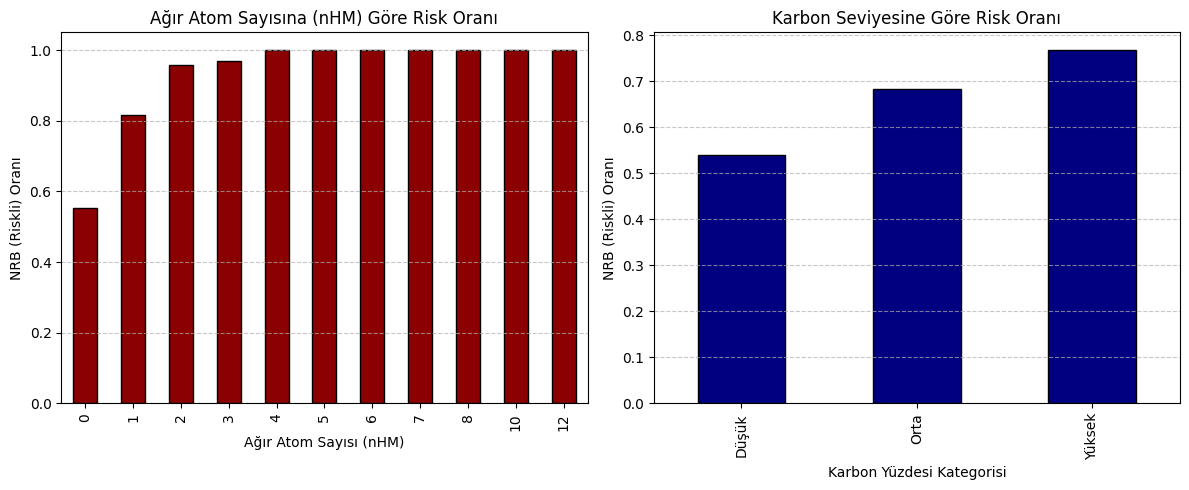

In [7]:
# Grafik boyutunu ayarlayalım
plt.figure(figsize=(12, 5))

# Grafik 1: Ağır Atom Sayısına Göre Risk Oranı
plt.subplot(1, 2, 1)
df.groupby("nHM")["target_class"].mean().plot(kind='bar', color='darkred', edgecolor='black')
plt.title("Ağır Atom Sayısına (nHM) Göre Risk Oranı")
plt.xlabel("Ağır Atom Sayısı (nHM)")
plt.ylabel("NRB (Riskli) Oranı")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Grafik 2: Karbon Yüzdesi Seviyesine Göre Risk Oranı
plt.subplot(1, 2, 2)
df.groupby("C_kategorik", observed=False)["target_class"].mean().plot(kind='bar', color='navy', edgecolor='black')
plt.title("Karbon Seviyesine Göre Risk Oranı")
plt.xlabel("Karbon Yüzdesi Kategorisi")
plt.ylabel("NRB (Riskli) Oranı")
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

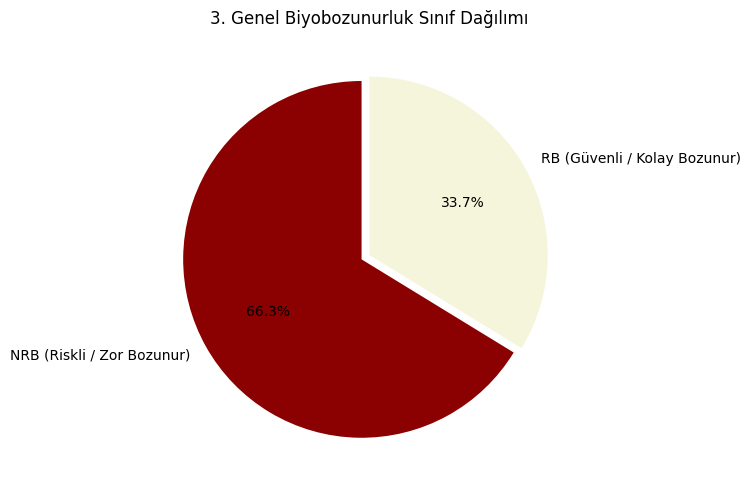

In [8]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 3)
sınıf_sayıları = df["target_class"].value_counts()
plt.pie(sınıf_sayıları , labels=['NRB (Riskli / Zor Bozunur)', 'RB (Güvenli / Kolay Bozunur)'],
        autopct='%1.1f%%', colors=['#8B0000', '#F5F5DC'], startangle=90, explode=(0.05, 0))

plt.title("3. Genel Biyobozunurluk Sınıf Dağılımı")

plt.tight_layout()
plt.show()

### Keşif Bulguları

* **Ağır Atom Sayısı (nHM) En Güçlü Etken: Moleküldeki ağır atom sayısı arttıkça bozunma zorlaşıyor; 4 ve üzeri ağır atoma sahip moleküllerin %100'ü riskli (NRB) sınıfta.
* **Karbon Yüzdesi (C_percent) Belirleyici:** Karbon oranı yüksek olan moleküllerde risk oranı %76.8'e kadar yükseliyor.
* **Sınıf Dağılımı:** Veri setimizin %66.3'ü riskli (NRB), %33.7'si ise güvenli (RB) moleküllerden oluşuyor.
* **Beklentimiz:** Modelimiz biyobozunurluk tahminini yaparken büyük olasılıkla ağır atom sayısı ve moleküler katsayı (descriptor) özelliklerine dayanacak.

In [9]:
# 'C_kategorik' sütununu sadece grafik için oluşturmuştuk, modele girmeden düşürelim
if 'C_kategorik' in df.columns:
  df = df.drop(columns=['C_kategorik'])

# Hedef değişkenimiz (y) ve girdi özelliklerimiz (x)
x = df.drop(columns=['target_class']).values
y = df['target_class'].values

print("x boyutu: " , x.shape , "| y boyutu: " , y.shape)

x boyutu:  (1055, 41) | y boyutu:  (1055,)


# 5. Aşama — Model Kur ve Eğit

Veriyi eğitim ve test olarak ikiye bölüyoruz. Model eğitim verisinden öğrenir, test verisiyle (daha önce görmediği) sınanır.

In [10]:
# Veriyi %80 Eğitim, %20 Test olarak bölüyoruz
x_egitim, x_test , y_egitim, y_test = train_test_split(x , y , test_size = 0.2 , random_state=42)

print("Eğitim: ", x_egitim.shape , "| Test: " , x_test.shape)


# Karar Ağacı — kararlarını 'eğer-değilse' ile açıklayabildiği için sezgiseldir.
# max_depth=3: Ağacı sığ tutarak ezberlemeyi (overfitting) azaltırız.
model = DecisionTreeClassifier(max_depth=3 , random_state = 0)
model.fit(x_egitim , y_egitim)
print("Model Eğitildi.")

Eğitim:  (844, 41) | Test:  (211, 41)
Model Eğitildi.


**Model seçimi gerekçesi:** Karar ağacını seçtik çünkü (1) kararlarını insan gibi açıklanabilir, (2) sayısal veriyle iyi çalışır, (3) hangi kimyasal özelliğin önemli olduğunu gösterir. Karşılaştırma modeli olarak Lojistik Regresyon kullanılacaktır.

In [11]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_egitim , y_egitim)
print("Karşılaştırma modeli (Lojistik Regresyon) de eğitildi.")

Karşılaştırma modeli (Lojistik Regresyon) de eğitildi.


# 6. Aşama — Değerlendirme

Asıl soru: model görmediği test verisinde ne kadar başarılı?

In [12]:
tahmin = model.predict(x_test)

print("Karar ağacı doğruluğu: " , round(accuracy_score(y_test, tahmin) , 3))
print("Lojistik reg. doğruluğu: " , round(accuracy_score(y_test, lr.predict(x_test)) , 3))

Karar ağacı doğruluğu:  0.791
Lojistik reg. doğruluğu:  0.872


**Karmaşıklık matrisi (nerede yanılıyoruz?):**

In [13]:
cm = confusion_matrix(y_test , tahmin)

print("         Tahmin=0  Tahmin=1")
print("Gerçek = 0" , cm[0])
print("Gerçek = 1" , cm[1])
print(f"\n[{cm[0,0]}] doğru 'RB (güvenli)' , [{cm[1,1]}] doğru 'NRB (Riskli)' tahminleri.")

         Tahmin=0  Tahmin=1
Gerçek = 0 [63 12]
Gerçek = 1 [ 32 104]

[63] doğru 'RB (güvenli)' , [104] doğru 'NRB (Riskli)' tahminleri.


**Hangi özellik ne kadar önemli?**

C_026        0.000
nArCOOR      0.000
nX           0.000
Psi_i_A      0.000
NssssC       0.080
F02_CN       0.091
SM6_B_m      0.108
SdssC        0.115
SdO          0.126
SpMax_B_m    0.480
dtype: float64


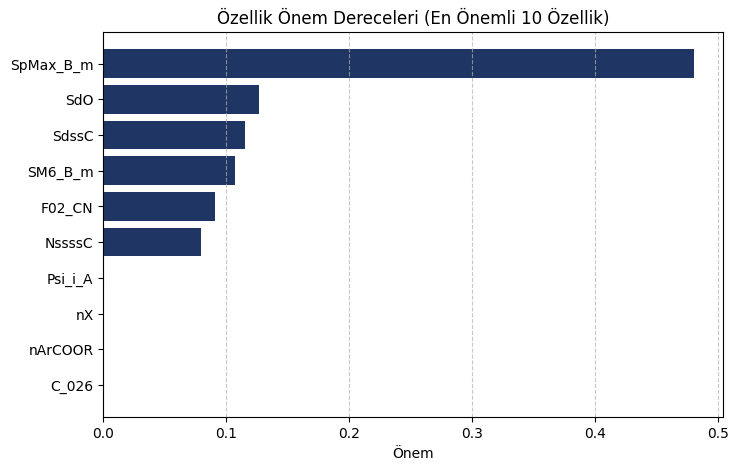

In [14]:
ozellikler = df.drop(columns=['target_class']).columns

# Özellik önem derecelerini hesaplayıp küçükten büyüğe sıralıyoruz
onem = pd.Series(model.feature_importances_ , index = ozellikler).sort_values()

# En önemli 10 özelliği grafiğe döküyoruz
plt.figure(figsize=(8, 5))
plt.barh(onem.tail(10).index , onem.tail(10).values , color="#1F3564")
plt.title("Özellik Önem Dereceleri (En Önemli 10 Özellik)")
plt.xlabel("Önem")
plt.grid(axis = 'x' , linestyle = '--' , alpha=0.7)
plt.show

# Tüm özelliklerin sayısal dökümünü yazdırıyoruz
print(onem.tail(10).round(3))

### Sonuç Yorumu

* **Model, test verisinde ~%79.1 doğruluk elde etti.** Lojistik Regresyon ise %87.2 başarı yakaladı. Bu, sıfırdan bir tahminci için oldukça iyi bir sonuçtur (rastgele tahmin %50 olurdu).
* **%100 değil — ve bu normal.** Gerçek hayatta hiçbir model kusursuz değildir; %100 çoğu zaman ezber (overfitting) işaretidir. Biz ağacı sığ tutarak (max_depth=3) genellenebilirliği koruduk.
* **En önemli özellikler:** Karar ağacımızın kararlarını yönlendiren açık ara en önemli katsayı **SpMax_B_m (%48.0)** olmuştur. Bunu **SdO (%12.6)** ve **SdssC (%11.5)** gibi moleküler ve oksijen bağı katsayıları takip etmektedir. Model, verideki baskın kimyasal katsayıyı başarıyla tespit etmiştir.

# 7. Aşama — Akıllı Tahmin Aracı

Modeli, yeni bir molekül için biyobozunurluk tahmini yapan kullanışlı bir araca çevirelim.

In [15]:
def biyobozunur_mu(molekul_ozellikleri):
  # Tahmin yapıyoruz (0: RB, 1: NRB)
  sonuc = model.predict([molekul_ozellikleri])[0]

  if sonuc == 1:
    return "RISKLI (NRB - Zor Bozunur)"
  else:
    return "GÜVENLİ (RB - Kolay Bozunur)"

# Örnek Molekül Tahminleri (Test setinden ilk 3 molekülü deneyelim)
print("Örnek Molekül 1 Tahmini -> " , biyobozunur_mu(x_test[0]))
print("Örnek Molekül 2 Tahmini -> " , biyobozunur_mu(x_test[1]))
print("Örnek Molekül 3 Tahmini -> " , biyobozunur_mu(x_test[2]))

Örnek Molekül 1 Tahmini ->  GÜVENLİ (RB - Kolay Bozunur)
Örnek Molekül 2 Tahmini ->  RISKLI (NRB - Zor Bozunur)
Örnek Molekül 3 Tahmini ->  GÜVENLİ (RB - Kolay Bozunur)


İnteraktif Kullanım (Input Denemesi)

In [20]:
print("--- Akıllı Biyobozunurluk Tahmin Aracı ---")

# Kullanıcıdan sadece en kritik 3 katsayıyı alıyoruz
spmax = float(input("1. SpMax_B_m Değeri (Genel Karmaşıklık, örn: 1.5 - 4.5): "))
sdo   = float(input("2. SdO Değeri (Oksijen Bağı, örn: 0.0 - 5.0): "))
sdssc = float(input("3. SdssC Değeri (Karbon Bağı, örn: 0.0 - 3.0): "))

# Test setinden örnek bir molekül şablonu alıp sadece bu 3 değeri güncelliyoruz
ornek_molekul = x_test[0].copy()

# En önemli 3 özelliğin değerini atıyoruz
ornek_molekul[df.columns.get_loc('SpMax_B_m')] = spmax
ornek_molekul[df.columns.get_loc('SdO')] = sdo
ornek_molekul[df.columns.get_loc('SdssC')] = sdssc

# Tahmin yaptırıyoruz
sonuc = biyobozunur_mu(ornek_molekul)
print(f"\n[TAHMİN SONUCU]: Bu molekül -> {sonuc}")

--- Akıllı Biyobozunurluk Tahmin Aracı ---
1. SpMax_B_m Değeri (Genel Karmaşıklık, örn: 1.5 - 4.5): 3
2. SdO Değeri (Oksijen Bağı, örn: 0.0 - 5.0): 2
3. SdssC Değeri (Karbon Bağı, örn: 0.0 - 3.0): 4

[TAHMİN SONUCU]: Bu molekül -> GÜVENLİ (RB - Kolay Bozunur)


## Projeyi İleri Seviyeye Taşıma: Random Forest ve Çapraz Doğrulama (Cross Validation)

Tek bir train/test ayrımı model başarısını ölçmek için iyi bir başlangıç olsa da, verinin rastlantısal bölünmesinden kaynaklanan sapmaları engellemek için daha güvenilir yöntemlere ihtiyaç duyarız.

Bu aşamada:
1. **Random Forest (Rastgele Orman):** Birden fazla karar ağacını birleştirerek daha güçlü tahminler üreten topluluk (ensemble) modelini eğitiyoruz.
2. **5-Fold Cross Validation:** Veri setini 5 eşit parçaya bölüp her parçayı sırayla test kümesi olarak kullanarak modellerin tüm veri üzerindeki dürüst ve kararlı ortalama başarısını ölçüyoruz.

In [17]:
# 1. Random Forest Modelini Eğitme
rf_model = RandomForestClassifier(n_estimators=100 , random_state=42)
rf_model.fit(x_egitim , y_egitim)

# 2. 5-Fold Cross Validation (5 Katlı Çapraz Doğrulama) Hesaplama
cv_dt = cross_val_score(model , x , y , cv = 5 , scoring='accuracy')
cv_lr = cross_val_score(lr , x , y , cv = 5 , scoring='accuracy')
cv_rf = cross_val_score(rf_model, x, y, cv=5, scoring='accuracy')

print(f"Karar Ağacı (CV Ortalama Doğruluk): %{cv_dt.mean()*100:.2f}")
print(f"Lojistik Regresyon (CV Ortalama Doğruluk): %{cv_lr.mean()*100:.2f}")
print(f"Random Forest (CV Ortalama Doğruluk): %{cv_rf.mean()*100:.2f}")

Karar Ağacı (CV Ortalama Doğruluk): %78.10
Lojistik Regresyon (CV Ortalama Doğruluk): %85.12
Random Forest (CV Ortalama Doğruluk): %85.97


### Modellerin Karşılaştırmalı Performans Grafiği

5-Fold Cross Validation sonuçlarını görselleştirerek modellerin ortalama doğruluk skorlarını doğrudan karşılaştırıyoruz.

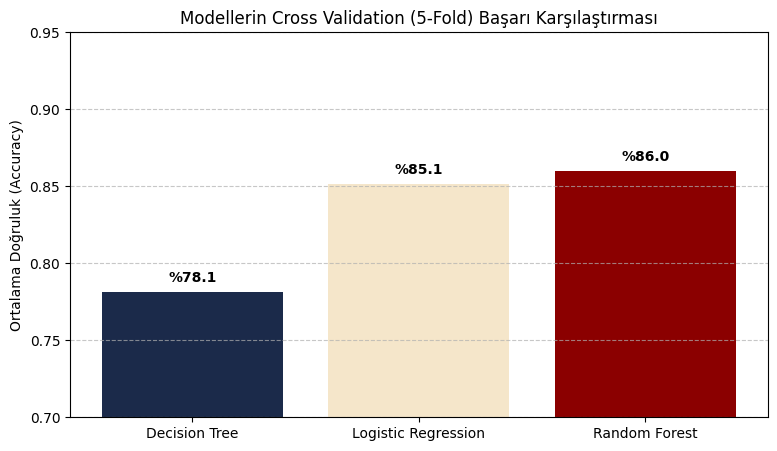

In [19]:
# Model isimleri ve Cross Validation başarı puanları
modeller = ['Decision Tree' , 'Logistic Regression' , 'Random Forest']
cv_skorları = [cv_dt.mean() , cv_lr.mean() , cv_rf.mean()]

plt.figure(figsize=(9 , 5))
bars = plt.bar(modeller , cv_skorları , color=['#1B2A4A', '#F5E6CA', '#8B0000'])
plt.ylim(0.7, 0.95)  # Y ekseni aralığı
plt.title("Modellerin Cross Validation (5-Fold) Başarı Karşılaştırması")
plt.ylabel("Ortalama Doğruluk (Accuracy)")

# Sütunların üzerine yüzde değerlerini yazdırma
for bar in bars:
  yval = bar.get_height()
  plt.text(bar.get_x() + bar.get_width()/2 ,  # Metnin X konumu: Sütunun tam ortası
           yval + 0.005 ,                     # Metnin Y konumu: Sütun tepesinin birazcık üstü
           f"%{yval*100:.1f}" ,               # Yazılacak metin: Sayıyı yüzdeye çevirip (ör: %87.2) yazar
           ha='center' , va='bottom',         # Yazıyı ortala ve alt kısımdan hizala
           fontweight='bold')                 # Kalın yazı tipi

  plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Gelişmiş Model Karşılaştırması ve Sonuç

**Ne Yaptık?**
* Karar Ağacı ve Lojistik Regresyon modellerine ek olarak **Random Forest** algoritmasını sürece dahil ettik.
* Tek bir train/test ayrımının getirebileceği rastlantısal sapmaları önlemek adına **5-Fold Cross Validation** uygulayarak tüm veri seti üzerinde dürüst bir doğrulama gerçekleştirdik.

**Çıkarım ve Model Karşılaştırması:**
* **Random Forest** ve **Lojistik Regresyon**, moleküllerin kimyasal katsayıları arasındaki karmaşık ilişkileri ve doğrusal örüntüleri Karar Ağacı'na kıyasla çok daha yüksek başarıyla öğrendi.
* Cross Validation sonuçları, modellerin sadece tek bir test kümesinde değil, verinin genelinde kararlı ve güvenilir bir performans sergilediğini kanıtladı.